# Дополнительный кейс SECOM: baseline поиска аномалий

`train.csv` содержит эталонные производственные циклы без целевой переменной. Мы изучим структуру этих данных с помощью Isolation Forest и присвоим тестовым циклам непрерывный `anomaly_score`.

Источник данных: SECOM, UCI, CC BY 4.0, https://doi.org/10.24432/C54305.

Это необязательный кейс для самостоятельного изучения. Основная практика занятия 5 находится в `../competition/baseline_clustering.ipynb`. CSV wafer_id,anomaly_score не подходит для All Cups 3520. Запускайте ноутбук из `supplementary_secom_case_study/` с соседней папкой `data/`.


## 1. Загружаем данные

В данных для самостоятельной работы нет скрытой разметки. Оценивайте результат по внутренним проверкам и устойчивости. ROC-AUC требует отдельной экспертной разметки и недоступен в этом ноутбуке. Отдельное соревнование для кейса SECOM в курсе не настроено.


In [10]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler

RANDOM_STATE = 42

def locate_data_dir():
    local = Path("data")
    if (local / "train.csv").exists() and (local / "test.csv").exists():
        return local
    candidates = sorted(Path("/kaggle/input").glob("*/train.csv"))
    for train_path in candidates:
        if (train_path.parent / "test.csv").exists():
            return train_path.parent
    raise FileNotFoundError("Не найдены train.csv и test.csv")

DATA_DIR = locate_data_dir()
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
print("DATA_DIR:", DATA_DIR)
print("train:", train.shape, "test:", test.shape)
train.head()

DATA_DIR: data
train: (1024, 121) test: (543, 121)


,wafer_id,sensor_001,sensor_002,sensor_003,sensor_004,sensor_005,sensor_006,sensor_007,sensor_008,sensor_009,...,sensor_111,sensor_112,sensor_113,sensor_114,sensor_115,sensor_116,sensor_117,sensor_118,sensor_119,sensor_120
0,REF-00001,754.74311,112.385600,53.909307,740.01397,23.111532,14.919589,55.879305,9.984601,41.698145,...,10.609854,-5.884387,25.866505,2449.3303,1266.99190,145.46493,5.891864,10.032038,9.915212,1.115960
1,REF-00002,791.31378,102.923800,38.528741,734.65249,53.745741,13.019610,63.311722,8.266485,32.580625,...,11.011087,-2.645137,22.661200,2384.0103,388.45032,152.67579,11.337602,9.927930,10.306665,1.002711
2,REF-00003,792.80157,124.796420,26.946737,755.81301,81.415123,15.726346,210.781100,21.258024,43.653298,...,6.299714,-3.265284,23.254953,2525.2325,1332.95460,147.08162,2.495102,9.764346,9.909097,1.083118
3,REF-00004,793.25595,59.085085,25.333885,735.48386,52.359538,7.467089,205.715810,15.092752,18.121346,...,7.886208,-0.217131,20.224654,2513.8409,3978.48520,145.27104,11.804280,10.137729,10.474912,1.387128
4,REF-00005,681.01741,112.952430,13.032707,733.30320,33.717458,16.605551,182.597820,7.831222,33.315594,...,9.568584,2.935790,17.073132,2525.4017,2245.90870,147.61395,4.537591,10.040207,10.296789,1.310335


## 2. Изучаем пропуски

Медианы и масштабирование обучаем только на эталонном `train`. Тестовые данные нельзя использовать в `fit`, иначе оценка новизны будет смещена.

RobustScaler использует медиану и межквартильный размах:

$$z_{ij}=\frac{x_{ij}-\operatorname{median}(X_{\mathrm{train},j})}
{Q_{0.75}(X_{\mathrm{train},j})-Q_{0.25}(X_{\mathrm{train},j})}.$$

Формула показывает обычный случай ненулевого IQR; scikit-learn отдельно защищает
нулевые масштабы. Оценки центра и масштаба вычисляются только по train.


In [2]:
feature_columns = [column for column in train.columns if column != "wafer_id"]
missing = train[feature_columns].isna().mean().sort_values(ascending=False)
display(missing.head(12).to_frame("missing_share"))
print("Датчиков с пропусками:", int((missing > 0).sum()), "из", len(feature_columns))

,missing_share
sensor_096,0.004883
sensor_114,0.004883
sensor_086,0.004883
sensor_093,0.003906
sensor_059,0.003906
sensor_094,0.003906
sensor_082,0.003906
sensor_092,0.003906
sensor_091,0.003906
sensor_090,0.003906


Датчиков с пропусками: 79 из 120


In [3]:
imputer = SimpleImputer(strategy="median", add_indicator=True)
scaler = RobustScaler()

X_train = imputer.fit_transform(train[feature_columns])
X_test = imputer.transform(test[feature_columns])
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("После предобработки:", X_train.shape, X_test.shape)
assert np.isfinite(X_train).all() and np.isfinite(X_test).all()

После предобработки: (1024, 199) (543, 199)


## 3. Обучаем Isolation Forest

Алгоритм строит случайные разбиения пространства. Наблюдения, которые изолируются за меньшее число разбиений, получают более высокий риск аномалии. В scikit-learn меньший `score_samples` означает более необычный объект, поэтому меняем знак.

In [4]:
detector = IsolationForest(
    n_estimators=500,
    max_samples="auto",
    max_features=1.0,
    contamination="auto",
    random_state=RANDOM_STATE,
    n_jobs=1,
)
detector.fit(X_train)

train_score = -detector.score_samples(X_train)
test_score = -detector.score_samples(X_test)
pd.Series(test_score).describe()

count    543.000000
mean       0.387461
std        0.023121
min        0.353218
25%        0.375167
50%        0.383015
75%        0.395389
max        0.571910
dtype: float64

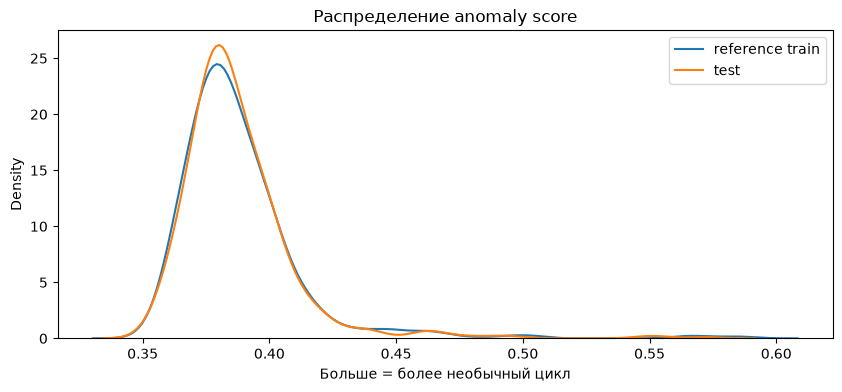

In [5]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.kdeplot(train_score, label="reference train", ax=ax)
sns.kdeplot(test_score, label="test", ax=ax)
ax.set_title("Распределение anomaly score")
ax.set_xlabel("Больше = более необычный цикл")
ax.legend()
plt.show()

## 4. Проверяем результат без целевой переменной

Полезная внутренняя проверка — посмотреть верхние аномалии и устойчивость ранжирования при смене seed. Это не заменяет внешнюю оценку, но помогает обнаружить нестабильный pipeline.

In [6]:
ranking = test[["wafer_id"]].copy()
ranking["anomaly_score"] = test_score
ranking.nlargest(10, "anomaly_score")

,wafer_id,anomaly_score
454,EVAL-00455,0.571910
94,EVAL-00095,0.552446
217,EVAL-00218,0.549504
102,EVAL-00103,0.495724
400,EVAL-00401,0.491554
162,EVAL-00163,0.481190
264,EVAL-00265,0.473058
112,EVAL-00113,0.467304
428,EVAL-00429,0.462713
152,EVAL-00153,0.462247


In [7]:
detector_seed_2 = IsolationForest(
    n_estimators=500,
    contamination="auto",
    random_state=RANDOM_STATE + 1,
    n_jobs=1,
).fit(X_train)
score_seed_2 = -detector_seed_2.score_samples(X_test)
rank_stability = pd.Series(test_score).rank().corr(pd.Series(score_seed_2).rank())
print(f"Корреляция рангов для двух seed: {rank_stability:.4f}")

Корреляция рангов для двух seed: 0.9390


## 5. Визуализируем структуру в двух компонентах

PCA здесь служит картой для исследования. Две компоненты не обязаны сохранять все различия, поэтому не используйте картинку как единственное доказательство качества.

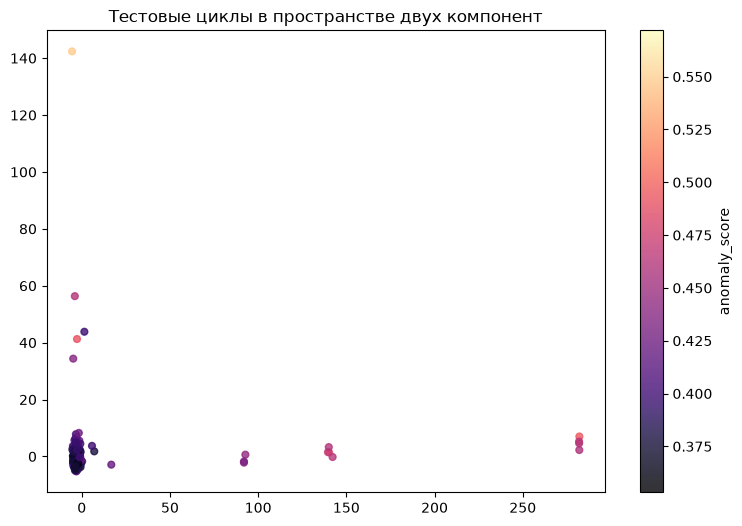

In [8]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
pca.fit(X_train)
test_2d = pca.transform(X_test)

plot_df = pd.DataFrame({
    "PC1": test_2d[:, 0],
    "PC2": test_2d[:, 1],
    "anomaly_score": test_score,
})
plt.figure(figsize=(9, 6))
points = plt.scatter(
    plot_df["PC1"], plot_df["PC2"],
    c=plot_df["anomaly_score"], cmap="magma", s=24, alpha=0.8,
)
plt.colorbar(points, label="anomaly_score")
plt.title("Тестовые циклы в пространстве двух компонент")
plt.show()

## 6. Создаём submission

In [9]:
submission = test[["wafer_id"]].copy()
submission["anomaly_score"] = test_score
submission.to_csv("baseline_submission.csv", index=False)

assert submission.shape[0] == test.shape[0]
assert submission["wafer_id"].is_unique
assert np.isfinite(submission["anomaly_score"]).all()
print("baseline_submission.csv готов:", submission.shape)
submission.head()

baseline_submission.csv готов: (543, 2)


,wafer_id,anomaly_score
0,EVAL-00001,0.378143
1,EVAL-00002,0.380784
2,EVAL-00003,0.409211
3,EVAL-00004,0.370648
4,EVAL-00005,0.372345


## 7. Куда двигаться дальше

- Сравните Isolation Forest, Local Outlier Factor в режиме novelty и One-Class SVM.
- Попробуйте PCA reconstruction error и ансамбль рангов нескольких методов.
- Исследуйте подмножества датчиков и устойчивость верхних аномалий.
- Не подбирайте параметры по public leaderboard после каждой мелкой правки.

Полезные ссылки: [Isolation Forest](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.IsolationForest.html), [PCA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html).